In [32]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append(os.path.abspath("../../../"))
from king_parametrization_binning.util.plot_verification_metrics import box_plot_binning_configs

In [33]:
run_file_split_sky = os.path.join('/data/user/fkrafft/all_sky_vs_split_sky_100configs', 'improvement_summary_split_sky.csv')
run_file_all_sky = os.path.join('/data/user/fkrafft/all_sky_vs_split_sky_100configs/all_sky', 'improvement_summary.csv')

In [34]:
split_df = pd.read_csv(run_file_split_sky, index_col= 0)
all_sky_df = pd.read_csv(run_file_all_sky, index_col = 0)
split_df.columns

Index(['run', 'sin_dec', 'disc_flux_ratio', 'sens_flux_ratio', 'ns_bias_ratio',
       'gamma_bias_ratio', 'n_bins', 'n_bins_energy', 'n_bins_dec',
       'n_bins_sigma'],
      dtype='str')

### 1. For each declination: Compare each metric

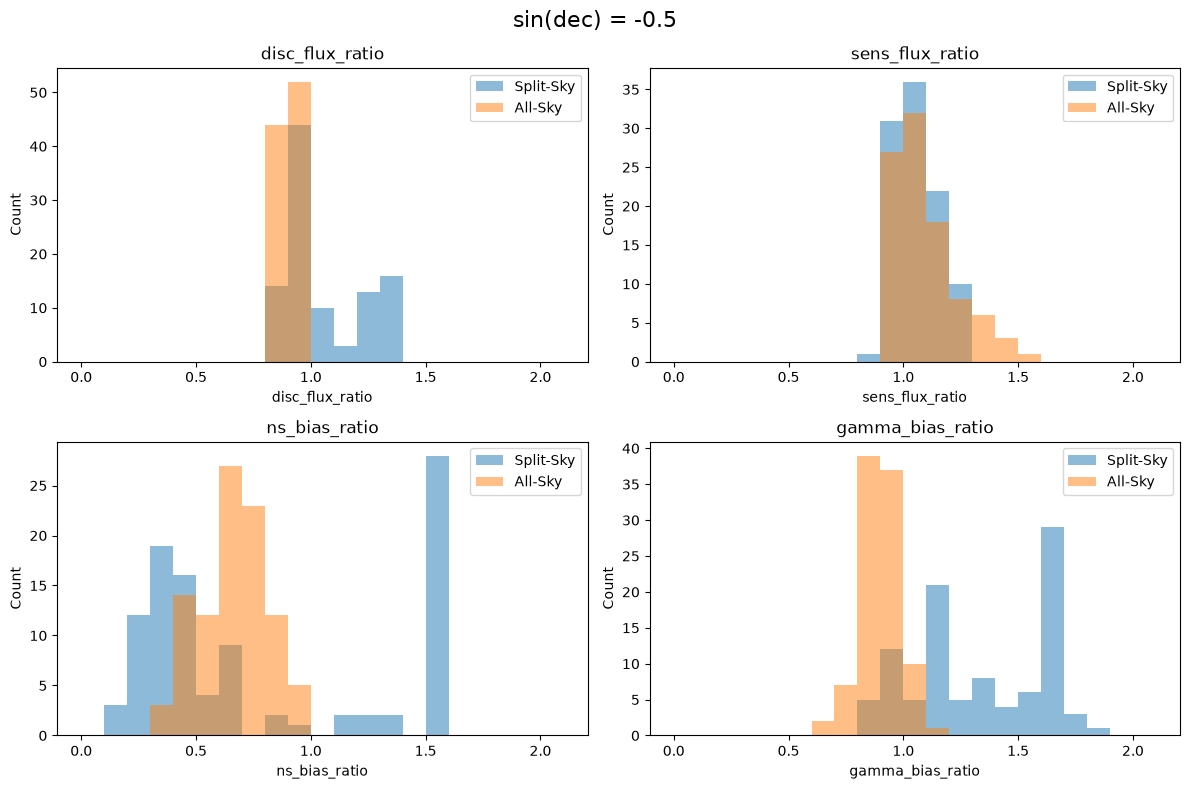

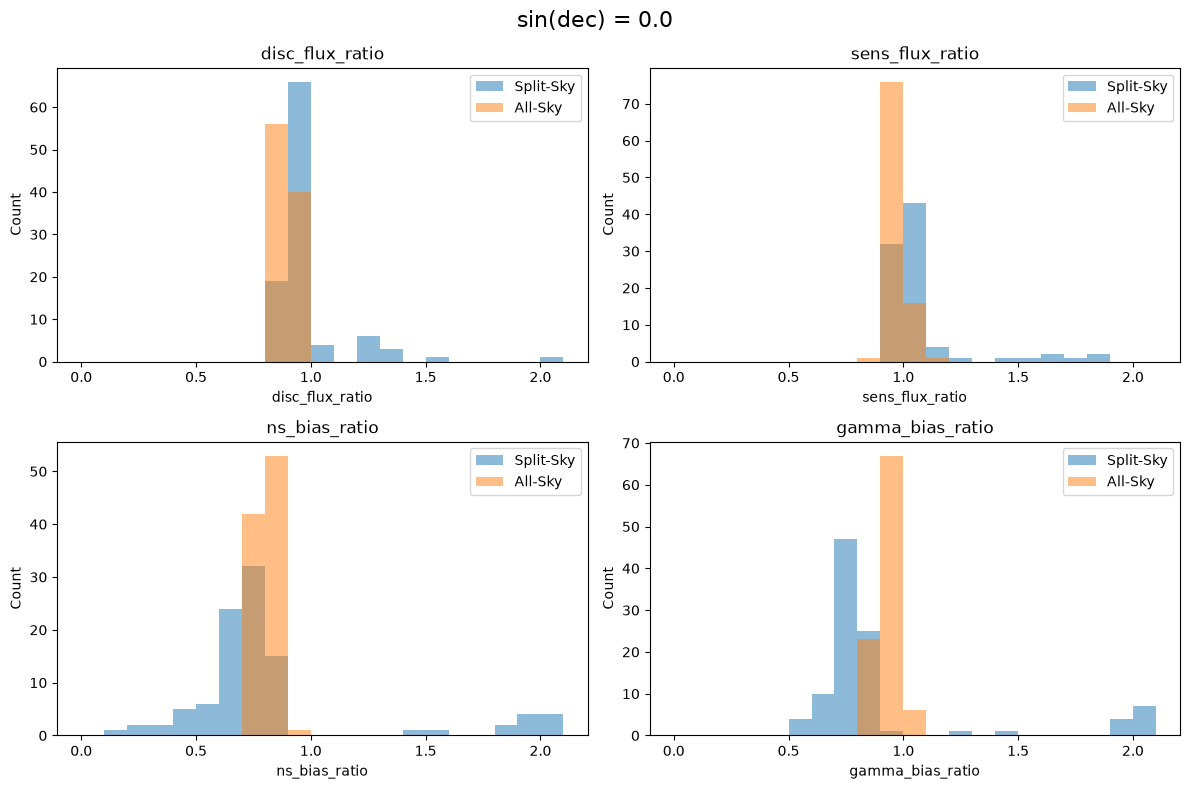

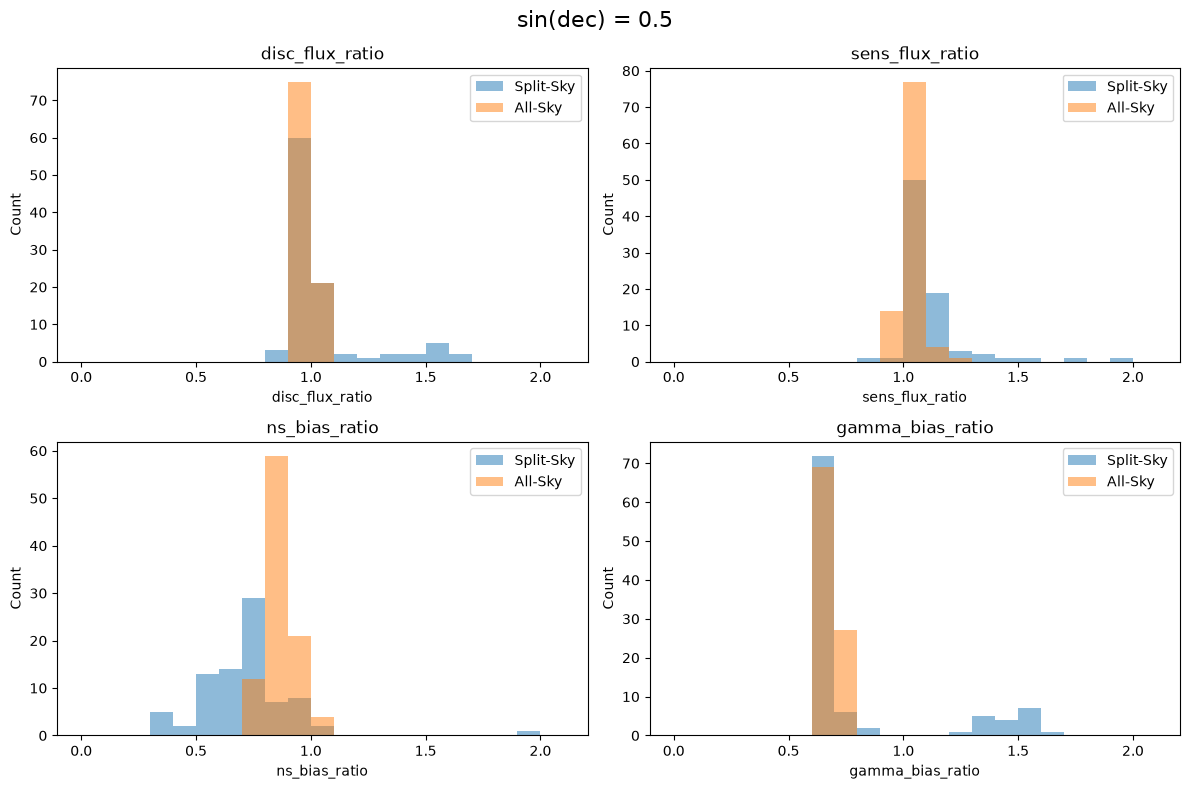

In [35]:
metrics = [
    "disc_flux_ratio",
    "sens_flux_ratio",
    "ns_bias_ratio",
    "gamma_bias_ratio",
]

sin_decs = sorted(split_df["sin_dec"].unique())

for sin_dec in sin_decs:

    # Select this sin_dec from both dataframes
    d1 = split_df[split_df["sin_dec"] == sin_dec]
    d2 = all_sky_df[all_sky_df["sin_dec"] == sin_dec]

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for ax, metric in zip(axes, metrics):

        # Common bins so the two histograms are directly comparable
        values = np.concatenate([
            d1[metric].dropna().values,
            d2[metric].dropna().values
        ])

        bins = np.append(np.linspace(0, 2, 21), 2.1)

        ax.hist(
            d1[metric],
            bins=bins,
            alpha=0.5,
            label="Split-Sky"
        )

        ax.hist(
            d2[metric],
            bins=bins,
            alpha=0.5,
            label="All-Sky"
        )

        ax.set_title(metric)
        ax.set_xlabel(metric)
        ax.set_ylabel("Count")
        ax.legend()

    fig.suptitle(f"sin(dec) = {sin_dec}", fontsize=16)

    plt.tight_layout()
    plt.show()

In [36]:
gamma_bias_thres = 1.3
sens_thres = 1.3
disc_pot_thres = 1.1
ns_bias_thres = 1.0

In [37]:
healthy_runs = split_df[(split_df['disc_flux_ratio'] < disc_pot_thres) &
                        (split_df['sens_flux_ratio'] < sens_thres) &
                        (split_df['gamma_bias_ratio'] < gamma_bias_thres) &
                        (split_df['ns_bias_ratio'] < ns_bias_thres)]

In [38]:
def rank_runs_by_bias(df):
    """
    Rank runs by their mean ns_bias_ratio across all sin_dec values.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns 'run' and 'ns_bias_ratio'.

    Returns
    -------
    pd.DataFrame
        Columns: rank, run, mean_ns_bias_ratio
    """
    ranking = (
        df.groupby("run", as_index=False)["ns_bias_ratio"]
        .mean()
        .rename(columns={"ns_bias_ratio": "mean_ns_bias_ratio"})
        .sort_values("mean_ns_bias_ratio")
        .reset_index(drop=True)
    )

    ranking.insert(0, "rank", range(1, len(ranking) + 1))

    return ranking

In [39]:
healthy_south_rank = rank_runs_by_bias(healthy_runs[healthy_runs['sin_dec'] == -0.5])
healthy_south_rank

,rank,run,mean_ns_bias_ratio
0,1,E15_D9_fc2efc_S20_MC300,0.179412
1,2,E10_D9_fc2efc_S05_MC300,0.207741
2,3,E100_D9_fc2efc_S05_MC300,0.218807
3,4,E50_D4_902b96_S05_MC300,0.230497
4,5,E5_D44_927d0d_S05_MC300,0.244811
5,6,E15_D44_927d0d_S05_MC300,0.246582
6,7,E10_D9_fc2efc_S30_MC300,0.248591
7,8,E30_D9_fc2efc_S10_MC300,0.249457
8,9,E100_D4_902b96_S15_MC300,0.251162
9,10,E20_D9_fc2efc_S05_MC300,0.272357


In [40]:
healthy_north_rank = rank_runs_by_bias(healthy_runs[healthy_runs['sin_dec'] > -0.5])
healthy_north_rank 

,rank,run,mean_ns_bias_ratio
0,1,E50_D14_fbbb47_S100_MC300,0.113984
1,2,E100_D44_9e6cc1_S15_MC300,0.216981
2,3,E20_D199_a71b5c_S15_MC300,0.356299
3,4,E50_D24_91ecd3_S50_MC300,0.402876
4,5,E10_D199_a71b5c_S30_MC300,0.448771
...,...,...,...
75,76,E10_D14_fbbb47_S50_MC300,0.884189
76,77,E50_D14_fbbb47_S30_MC300,0.885752
77,78,E5_D14_fbbb47_S30_MC300,0.886203
78,79,E15_D14_fbbb47_S100_MC300,0.890640


Best southern sky binning

In [41]:
south_best = healthy_runs[healthy_runs['run'] == healthy_south_rank['run'][0]][healthy_runs['sin_dec'] == -0.5]
south_best

/tmp/ipykernel_235473/3859486199.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  south_best = healthy_runs[healthy_runs['run'] == healthy_south_rank['run'][0]][healthy_runs['sin_dec'] == -0.5]


,run,sin_dec,disc_flux_ratio,sens_flux_ratio,ns_bias_ratio,gamma_bias_ratio,n_bins,n_bins_energy,n_bins_dec,n_bins_sigma
200,E15_D9_fc2efc_S20_MC300,-0.5,1.000963,0.935772,0.179412,0.864735,2700,15,9,20


Best northern sky binning

In [42]:
north_best = healthy_runs[healthy_runs['run'] == healthy_north_rank['run'][5]][healthy_runs['sin_dec'] > -0.5]
north_best

/tmp/ipykernel_235473/3451615838.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  north_best = healthy_runs[healthy_runs['run'] == healthy_north_rank['run'][5]][healthy_runs['sin_dec'] > -0.5]


,run,sin_dec,disc_flux_ratio,sens_flux_ratio,ns_bias_ratio,gamma_bias_ratio,n_bins,n_bins_energy,n_bins_dec,n_bins_sigma
101,E10_D9_11eb99_S05_MC300,0.0,0.893421,0.960809,0.444674,0.661784,450,10,9,5
102,E10_D9_11eb99_S05_MC300,0.5,1.030278,1.030645,0.485399,0.692308,450,10,9,5


combined mean for both skies:

In [43]:
best_bias_config_split_sky = pd.concat([south_best, north_best])
best_bias_config_split_sky

,run,sin_dec,disc_flux_ratio,sens_flux_ratio,ns_bias_ratio,gamma_bias_ratio,n_bins,n_bins_energy,n_bins_dec,n_bins_sigma
200,E15_D9_fc2efc_S20_MC300,-0.5,1.000963,0.935772,0.179412,0.864735,2700,15,9,20
101,E10_D9_11eb99_S05_MC300,0.0,0.893421,0.960809,0.444674,0.661784,450,10,9,5
102,E10_D9_11eb99_S05_MC300,0.5,1.030278,1.030645,0.485399,0.692308,450,10,9,5


In [44]:
best_split_sky_mean_bias = np.mean(best_bias_config_split_sky['ns_bias_ratio'])
best_split_sky_mean_bias

np.float64(0.36982836171556616)

In [45]:
healthy_all_sky = all_sky_df[(all_sky_df['disc_flux_ratio'] < disc_pot_thres) &
                        (all_sky_df['sens_flux_ratio'] < sens_thres) &
                        (all_sky_df['gamma_bias_ratio'] < gamma_bias_thres) &
                        (all_sky_df['ns_bias_ratio'] < ns_bias_thres)]

In [46]:
all_sky_ranking = rank_runs_by_bias(all_sky_df)
all_sky_ranking

,rank,run,mean_ns_bias_ratio
0,1,E8_b26d8e_D24_f8ce7a_S10_MC300,0.675796
1,2,E25_86544b_D24_f8ce7a_S50_MC300,0.676397
2,3,E13_e0c494_D14_f505b9_S10_MC300,0.681941
3,4,E25_86544b_D49_76f754_S10_MC300,0.684690
4,5,E8_a408dd_D14_f505b9_S10_MC300,0.687561
...,...,...,...
91,92,E25_86544b_D49_76f754_S100_MC300,0.865304
92,93,E8_a408dd_D49_76f754_S20_MC300,0.869488
93,94,E25_86544b_D9_83b58e_S25_MC300,0.873371
94,95,E13_e0c494_D9_83b58e_S50_MC300,0.883221


In [47]:
best_bias_config_all_sky = all_sky_df[all_sky_df['run'] == 'E8_b26d8e_D24_f8ce7a_S10_MC300']
best_bias_config_all_sky

,run,sin_dec,disc_flux_ratio,sens_flux_ratio,ns_bias_ratio,gamma_bias_ratio,n_bins,n_bins_energy,n_bins_dec,n_bins_sigma
219,E8_b26d8e_D24_f8ce7a_S10_MC300,-0.5,0.893421,0.950053,0.445337,0.855958,1920,8,24,10
220,E8_b26d8e_D24_f8ce7a_S10_MC300,0.0,0.887127,0.955745,0.766511,0.892680,1920,8,24,10
221,E8_b26d8e_D24_f8ce7a_S10_MC300,0.5,1.017313,1.014285,0.815539,0.651282,1920,8,24,10


## Compare statistics of performance metrics across healthy scans

### All-Sky

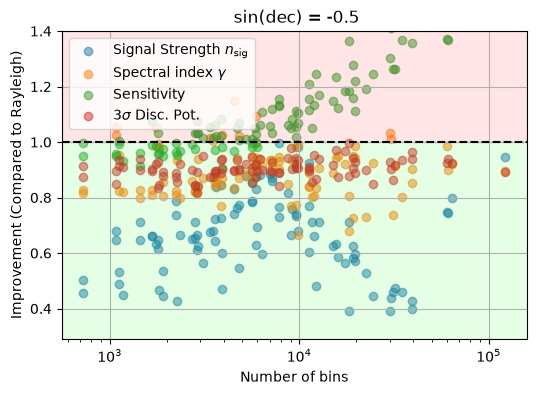

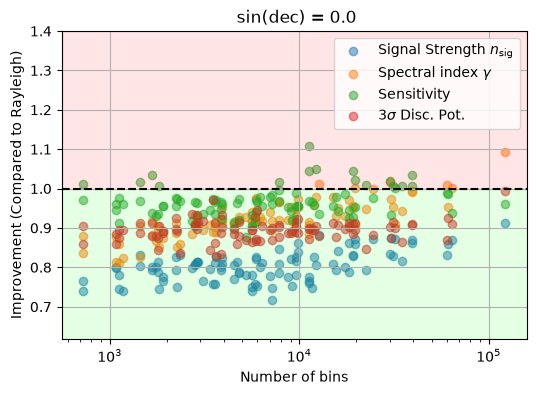

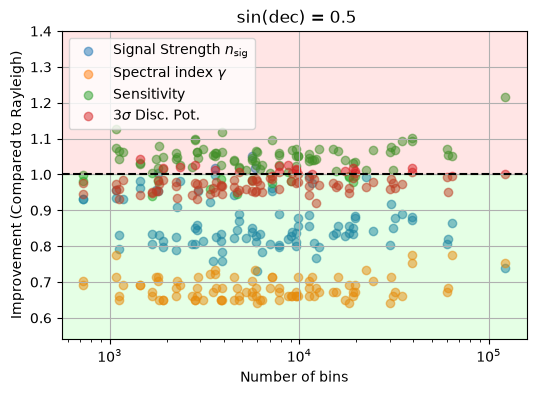

In [50]:

for sin_dec in [-0.5, 0.0, 0.5]:

    # Filter DataFrame for current sin(dec)
    df = all_sky_df[all_sky_df['sin_dec'] == sin_dec]

    max_bias = np.max([df['ns_bias_ratio'].max(), df['gamma_bias_ratio'].max()])
    min_bias = np.min([df['ns_bias_ratio'].min(), df['gamma_bias_ratio'].min()])

    max_flux_ratio = np.max([df['sens_flux_ratio'].max(), df['disc_flux_ratio'].max()])
    min_flux_ratio = np.min([df['sens_flux_ratio'].min(), df['disc_flux_ratio'].min()])

    max_ratio = 1.3
    min_ratio = np.min([min_bias, min_flux_ratio])

    plt.figure(figsize=(6, 4))
    plt.grid()
    plt.title(' sin(dec) = ' + str(sin_dec))

    plt.scatter(df['n_bins'], df['ns_bias_ratio'],
                alpha=0.5, label=r'Signal Strength $n_{\text{sig}}$')

    plt.scatter(df['n_bins'], df['gamma_bias_ratio'],
                alpha=0.5, label=r'Spectral index $\gamma$')

    plt.scatter(df['n_bins'], df['sens_flux_ratio'],
                alpha=0.5, label='Sensitivity')

    plt.scatter(df['n_bins'], df['disc_flux_ratio'],
                alpha=0.5, label=r'3$\sigma$ Disc. Pot.')

    plt.xlabel('Number of bins')
    plt.ylabel('Improvement (Compared to Rayleigh)')

    plt.ylim(min_ratio - 0.1, max_ratio + 0.1)

    plt.axhline(1, linestyle='dashed', color='black')
    plt.axhspan(1, max_ratio + 0.1, color='red', alpha=0.1)
    plt.axhspan(min_ratio - 0.1, 1, color='lime', alpha=0.1)

    plt.xscale('log')
    plt.legend()
    plt.show()

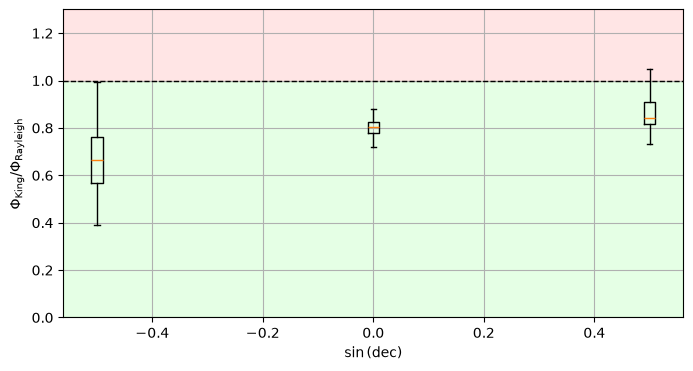

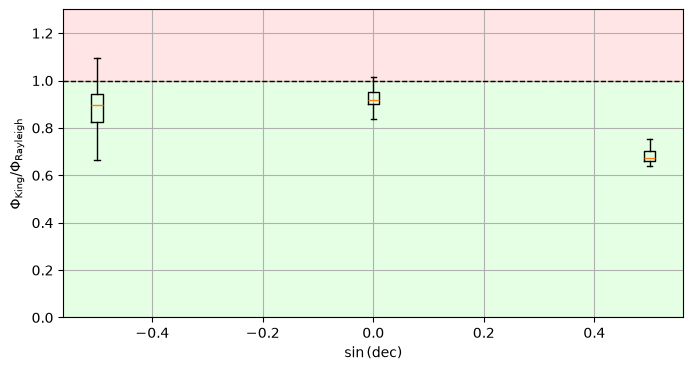

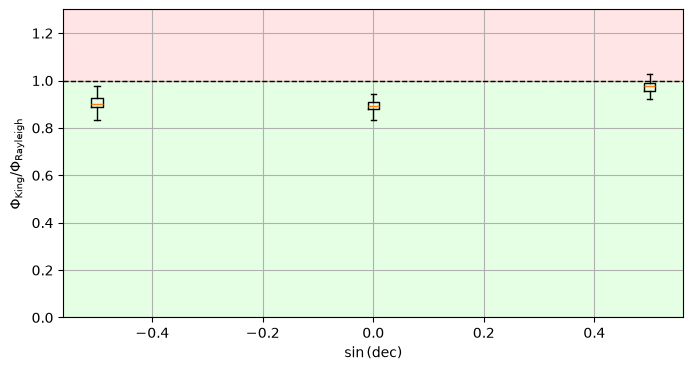

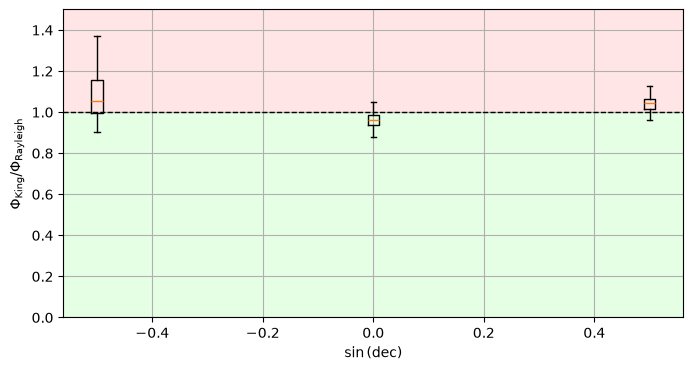

In [ ]:
box_plot_binning_configs(all_sky_df, 'ns_bias_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.3])
box_plot_binning_configs(all_sky_df, 'gamma_bias_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.3])
box_plot_binning_configs(all_sky_df, 'disc_flux_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.3])
box_plot_binning_configs(all_sky_df, 'sens_flux_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.5])

### Sky-split

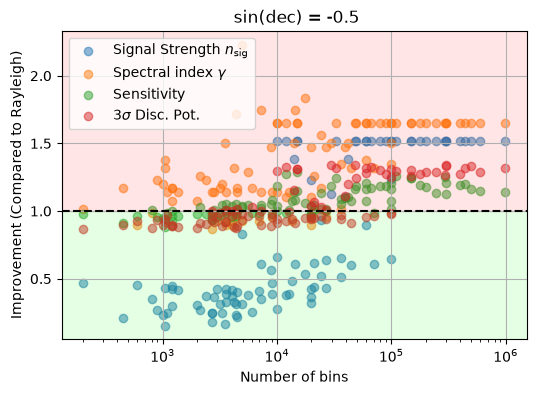

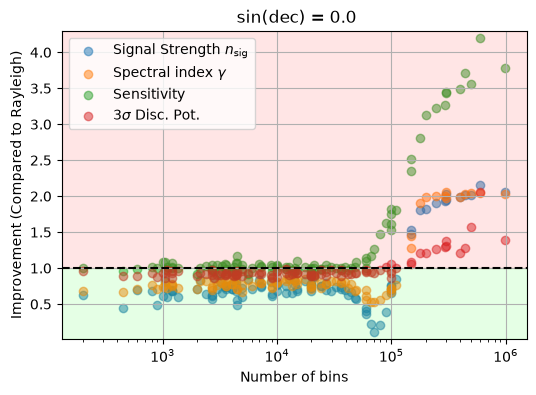

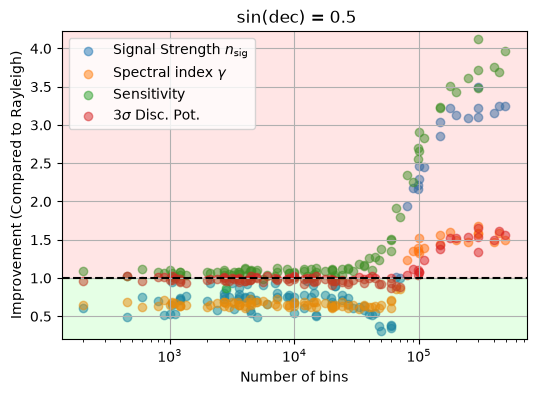

In [51]:

for sin_dec in [-0.5, 0.0, 0.5]:

    # Filter DataFrame for current sin(dec)
    df = split_df[split_df['sin_dec'] == sin_dec]

    max_bias = np.max([df['ns_bias_ratio'].max(), df['gamma_bias_ratio'].max()])
    min_bias = np.min([df['ns_bias_ratio'].min(), df['gamma_bias_ratio'].min()])

    max_flux_ratio = np.max([df['sens_flux_ratio'].max(), df['disc_flux_ratio'].max()])
    min_flux_ratio = np.min([df['sens_flux_ratio'].min(), df['disc_flux_ratio'].min()])

    max_ratio = np.max([max_bias, max_flux_ratio])
    min_ratio = np.min([min_bias, min_flux_ratio])

    plt.figure(figsize=(6, 4))
    plt.grid()
    plt.title(' sin(dec) = ' + str(sin_dec))

    plt.scatter(df['n_bins'], df['ns_bias_ratio'],
                alpha=0.5, label=r'Signal Strength $n_{\text{sig}}$')

    plt.scatter(df['n_bins'], df['gamma_bias_ratio'],
                alpha=0.5, label=r'Spectral index $\gamma$')

    plt.scatter(df['n_bins'], df['sens_flux_ratio'],
                alpha=0.5, label='Sensitivity')

    plt.scatter(df['n_bins'], df['disc_flux_ratio'],
                alpha=0.5, label=r'3$\sigma$ Disc. Pot.')

    plt.xlabel('Number of bins')
    plt.ylabel('Improvement (Compared to Rayleigh)')

    plt.ylim(min_ratio - 0.1, max_ratio + 0.1)

    plt.axhline(1, linestyle='dashed', color='black')
    plt.axhspan(1, max_ratio + 0.1, color='red', alpha=0.1)
    plt.axhspan(min_ratio - 0.1, 1, color='lime', alpha=0.1)

    plt.xscale('log')
    plt.legend()
    plt.show()

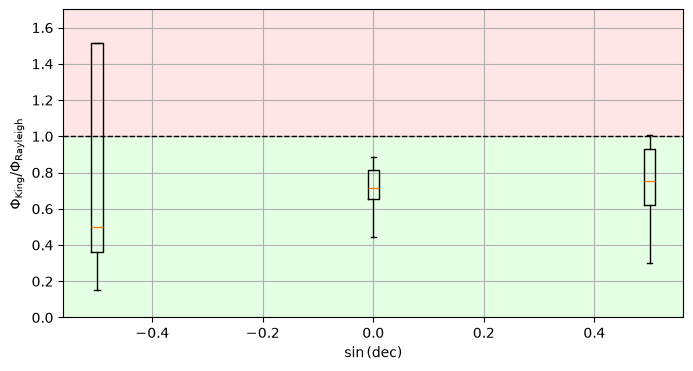

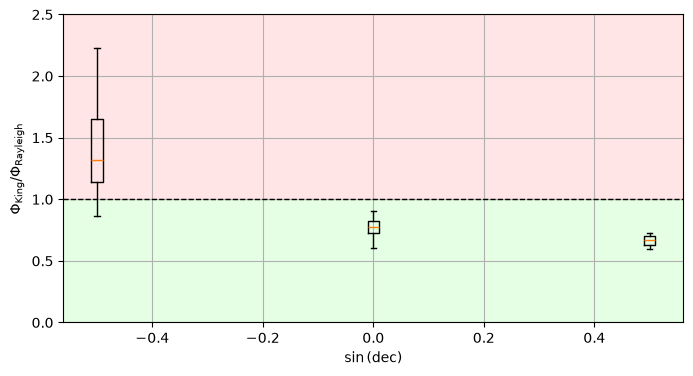

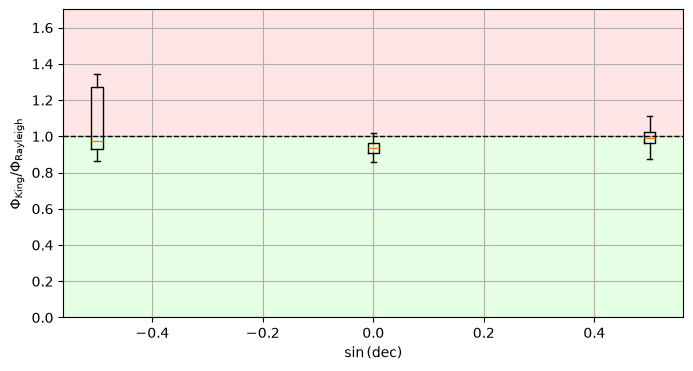

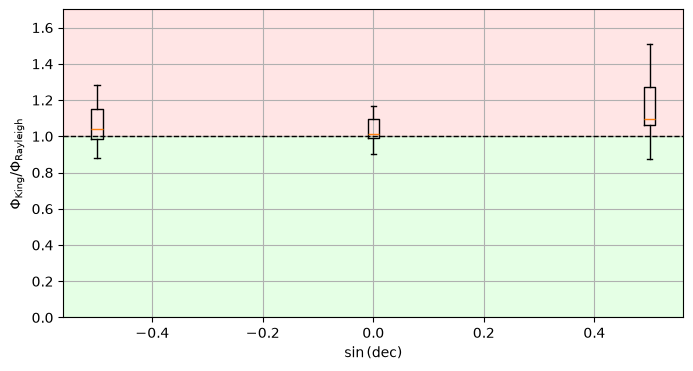

In [ ]:
box_plot_binning_configs(split_df, 'ns_bias_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.7])
box_plot_binning_configs(split_df, 'gamma_bias_ratio', [-0.5, 0.0, 0.5], ylim = [0., 2.5])
box_plot_binning_configs(split_df, 'disc_flux_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.7])
box_plot_binning_configs(split_df, 'sens_flux_ratio', [-0.5, 0.0, 0.5], ylim = [0., 1.7])